# RespiraCidadão: Machine Learning & Modelling (`GS 2026.2`)

**Sala:** `1TIAPZ1` | **Grupo:** `Perceptron`  
**Integrantes:**
- Giovanni Henrique Pereira Hessel (RM 570574)
- Suellen Pereira da Silva (RM 573862)
- Israel Carneiro de Toledo (RM 573854)

---

## 1. Entendimento do Problema, Público e Dados
- **Problema:** Episódios de poluição atmosférica e fumaça urbana elevam a concentração de monóxido de carbono (`CO`), benzeno (`C6H6`) e óxidos de nitrogênio (`NOx`/`NO2`), agravando crises respiratórias em escolas, UBS e residências vulneráveis.
- **Público beneficiado:** Crianças, idosos e pacientes com asma/DPOC em áreas urbanas e periferias monitoradas pela rede CitizenTech RespiraCidadão.
- **ODS relacionados:** ODS 3 (Saúde e Bem-Estar), ODS 10 (Redução das Desigualdades) e ODS 11 (Cidades e Comunidades Sustentáveis).
- **Base de dados:** *UCI Air Quality Dataset* (Vito et al., 2008), base real com **9.357 registros horários** de sensores óxido-metálicos (`PT08.S1` a `PT08.S5`), analisadores de referência e microclima (`T`, `RH`, `AH`).
- **Tarefa supervisionada:** Classificação multiclasse de risco respiratório baseada na concentração real de referência `CO(GT)` (excluída das variáveis de entrada para evitar *data leakage*):
  - `0`: normal: `CO(GT) < 1.5 mg/m³`
  - `1`: atencao: `1.5 <= CO(GT) < 3.0 mg/m³`
  - `2`: critico: `CO(GT) >= 3.0 mg/m³`

In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "figure.facecolor": "#0f0f12",
    "axes.facecolor": "#1c1c21",
    "axes.edgecolor": "#3a3a45",
    "axes.labelcolor": "#e5e9f0",
    "text.color": "#e5e9f0",
    "xtick.color": "#acc1cc",
    "ytick.color": "#acc1cc",
    "grid.color": "#2a2a33",
})

ROOT = Path.cwd().resolve()
if ROOT.name == "ml-modelling":
    ROOT = ROOT.parents[1]

DATA_PATH = ROOT / "data" / "processed" / "air_quality_clean.csv"
OUT_DIR = ROOT / "packages" / "ml-modelling"
CHARTS_DIR = OUT_DIR / "charts"
ARTIFACTS_DIR = OUT_DIR / "artifacts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
]
CLASS_NAMES = ["normal", "atencao", "critico"]

df = pd.read_csv(DATA_PATH)
print(f"Dataset limpo carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head(5)

Dataset limpo carregado: 6941 linhas x 17 colunas


,Date,Time,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,nivel_risco_id,nivel_risco,alerta_critico
0,10/03/2004,18.00.00,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,1,atencao,0
1,10/03/2004,19.00.00,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,1,atencao,0
2,10/03/2004,20.00.00,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,1,atencao,0
3,10/03/2004,21.00.00,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,1,atencao,0
4,10/03/2004,22.00.00,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,1,atencao,0


## 2. Análise Exploratória de Dados (EDA) e Qualidade
Verificamos valores ausentes (já tratados na limpeza dos códigos `-200` e remoção de `NMHC(GT)` que possuía 90% de ausência no equipamento original), balanceamento das classes de risco e correlações entre sensores e poluentes.

Valores ausentes por coluna:
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
CO(GT)           0
nivel_risco      0
dtype: int64

Distribuição das classes de risco:
nivel_risco
atencao    2718
normal     2531
critico    1692
Name: count, dtype: int64


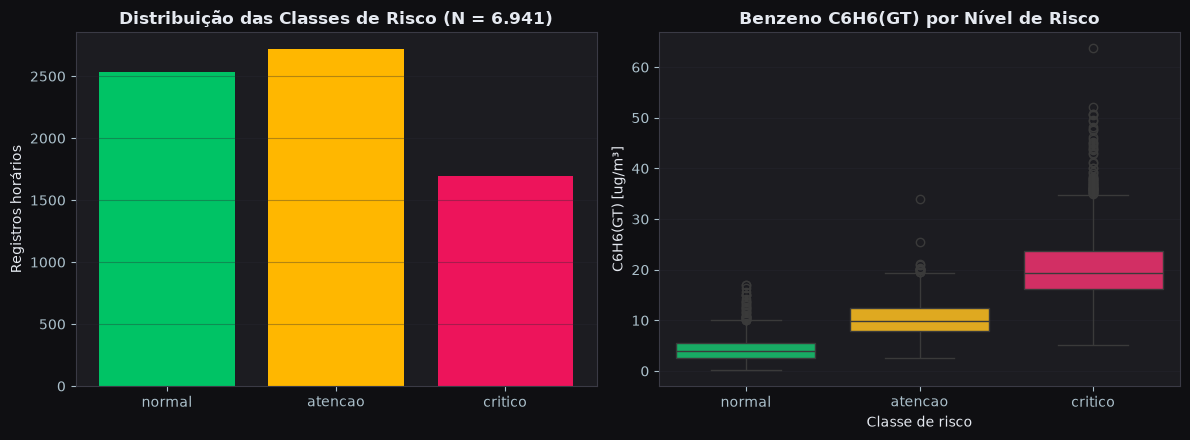

In [2]:
print("Valores ausentes por coluna:")
print(df[FEATURES + ["CO(GT)", "nivel_risco"]].isna().sum())
print("\nDistribuição das classes de risco:")
print(df["nivel_risco"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = df["nivel_risco"].value_counts().reindex(CLASS_NAMES)
axes[0].bar(counts.index, counts.values, color=["#00C365", "#FFB700", "#ED145B"])
axes[0].set_title("Distribuição das Classes de Risco (N = 6.941)", fontweight="bold")
axes[0].set_ylabel("Registros horários")
axes[0].grid(axis="y", alpha=0.35)

sns.boxplot(data=df, x="nivel_risco", y="C6H6(GT)", order=CLASS_NAMES,
            palette=["#00C365", "#FFB700", "#ED145B"], ax=axes[1])
axes[1].set_title("Benzeno C6H6(GT) por Nível de Risco", fontweight="bold")
axes[1].set_xlabel("Classe de risco")
axes[1].set_ylabel("C6H6(GT) [ug/m³]")
axes[1].grid(axis="y", alpha=0.35)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_eda_classes_box.png", dpi=150)
plt.show()

## 3. Pré-processamento sem Data Leakage
- Separamos `X` (11 variáveis dos sensores e microclima) e `y` (`nivel_risco_id`: 0, 1, 2).
- `CO(GT)` é usado apenas para definir o rótulo `y` e **não entra em `X`**, eliminando vazamento do alvo.
- Divisão estratificada `80% treino / 20% teste` (`random_state=42`).
- `StandardScaler` é aplicado **dentro de `Pipeline`** ajustado exclusivamente nos folds de treino.

In [3]:
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df["nivel_risco_id"].to_numpy(dtype=np.int64)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")

Treino: (5552, 11) | Teste: (1389, 11)


## 4. Comparação de Algoritmos (Baseline + Modelos Não Lineares)
Comparamos 5 algoritmos da disciplina:
1. **Regressão Logística (Baseline linear):** referência simples e interpretável.
2. **KNN (`k=9`):** classificador por proximidade no espaço padronizado dos sensores.
3. **Árvore de Decisão (`max_depth=10`):** captura regras não lineares com risco controlado de profundidade.
4. **Random Forest:** ensemble bagging robusto a ruído de sensores.
5. **Gradient Boosting:** ensemble sequencial de árvores para fronteiras finas entre `atencao` e `critico`.

In [4]:
candidates = {
    "LogisticRegression (Baseline)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1500, random_state=42)),
    ]),
    "KNN (k=9)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=9)),
    ]),
    "DecisionTree (depth=10)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=10, min_samples_leaf=8, random_state=42)),
    ]),
    "RandomForest (default)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)),
    ]),
    "GradientBoosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingClassifier(random_state=42)),
    ]),
}

comparison = []
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    tr_pred = pipe.predict(X_train)
    te_pred = pipe.predict(X_test)
    comparison.append({
        "modelo": name,
        "train_acc": round(float(accuracy_score(y_train, tr_pred)), 4),
        "test_acc": round(float(accuracy_score(y_test, te_pred)), 4),
        "test_f1_macro": round(float(f1_score(y_test, te_pred, average="macro")), 4),
        "gap_overfit": round(float(accuracy_score(y_train, tr_pred) - accuracy_score(y_test, te_pred)), 4),
    })

comp_df = pd.DataFrame(comparison).sort_values("test_f1_macro", ascending=False)
comp_df

,modelo,train_acc,test_acc,test_f1_macro,gap_overfit
3,RandomForest (default),1.0000,0.8934,0.8954,0.1066
4,GradientBoosting,0.9216,0.8906,0.8928,0.0311
1,KNN (k=9),0.9063,0.8877,0.8897,0.0187
0,LogisticRegression (Baseline),0.8772,0.8855,0.8871,-0.0084
2,DecisionTree (depth=10),0.9215,0.8647,0.8676,0.0568


### Leitura da comparação
- A **Regressão Logística (baseline linear)** já atinge `88,55%` de acurácia no teste e `F1-macro = 0,8871`. Os modelos não lineares ficam entre `86,47%` (Árvore) e `89,34%` (Random Forest): o ganho máximo sobre o baseline é de cerca de `0,8` ponto percentual.
- Com `1.389` amostras de teste, o erro-padrão da acurácia é de aproximadamente `0,85 p.p.`; logo, **a diferença entre Random Forest, Gradient Boosting, KNN e Regressão Logística não é estatisticamente relevante**. O limite de desempenho parece vir dos dados (sensores de óxido metálico com deriva e ruído), não da escolha do algoritmo.

## 5. Otimização de Hiperparâmetros (`RandomizedSearchCV` com CV=5)
Aplicamos busca aleatória estratificada (5 folds) sobre o **Random Forest** para equilibrar poder preditivo e controle de overfitting (`max_depth`, `min_samples_leaf`, `max_features`, `n_estimators`).

In [5]:
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1)),
])

param_dist = {
    "model__n_estimators": [150, 250, 350],
    "model__max_depth": [10, 14, 18, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2", 0.6],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    rf_pipe,
    param_distributions=param_dist,
    n_iter=16,
    cv=cv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

best_pipe = search.best_estimator_
best_tr_pred = best_pipe.predict(X_train)
best_te_pred = best_pipe.predict(X_test)

tuned_row = {
    "modelo": "RandomForest (Tuned CV=5)",
    "train_acc": round(float(accuracy_score(y_train, best_tr_pred)), 4),
    "test_acc": round(float(accuracy_score(y_test, best_te_pred)), 4),
    "test_f1_macro": round(float(f1_score(y_test, best_te_pred, average="macro")), 4),
    "gap_overfit": round(float(accuracy_score(y_train, best_tr_pred) - accuracy_score(y_test, best_te_pred)), 4),
}
print("Melhores hiperparâmetros:", search.best_params_)
print("CV F1-macro médio:", round(float(search.best_score_), 4))
print("Desempenho no conjunto de teste:", tuned_row)
print("\nRelatório de Classificação (Teste):")
print(classification_report(y_test, best_te_pred, target_names=CLASS_NAMES))

Melhores hiperparâmetros: {'model__n_estimators': 250, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
CV F1-macro médio: 0.8921
Desempenho no conjunto de teste: {'modelo': 'RandomForest (Tuned CV=5)', 'train_acc': 0.9867, 'test_acc': 0.8906, 'test_f1_macro': 0.8922, 'gap_overfit': 0.0961}

Relatório de Classificação (Teste):
              precision    recall  f1-score   support

      normal       0.93      0.90      0.92       506
     atencao       0.85      0.88      0.86       544
     critico       0.90      0.89      0.90       339

    accuracy                           0.89      1389
   macro avg       0.89      0.89      0.89      1389
weighted avg       0.89      0.89      0.89      1389



## 6. Avaliação de Generalização, Matriz de Confusão e Feature Importance
Analisamos a matriz de confusão no conjunto de teste e a importância das variáveis para validar aderência física ao problema ambiental.

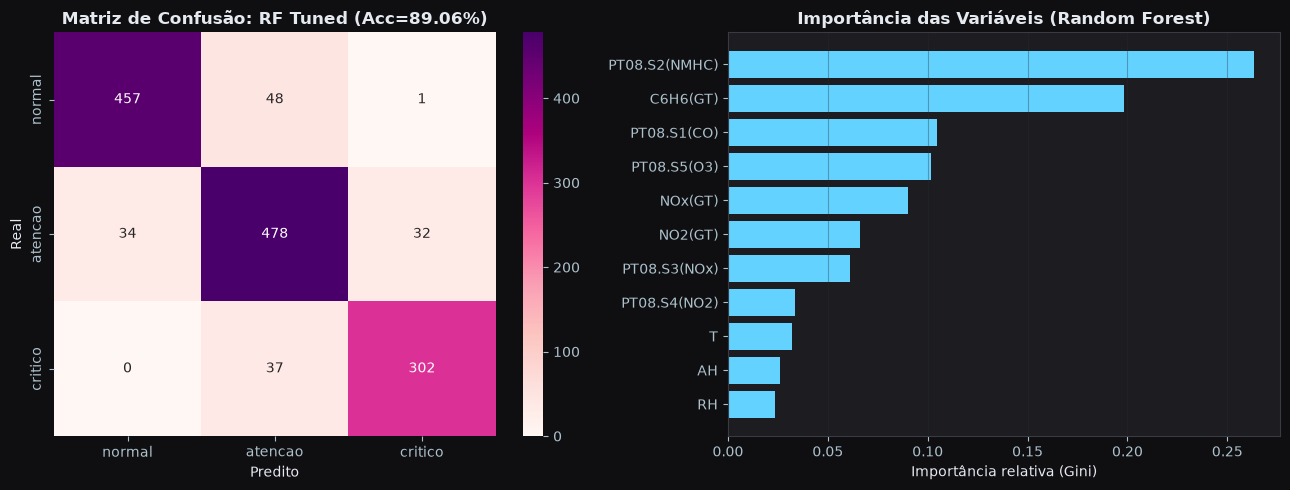

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, best_te_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="RdPu",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Matriz de Confusão: RF Tuned (Acc={tuned_row['test_acc']:.2%})", fontweight="bold")
axes[0].set_xlabel("Predito")
axes[0].set_ylabel("Real")

importances = best_pipe.named_steps["model"].feature_importances_
imp_df = pd.DataFrame({"feature": FEATURES, "importance": importances}).sort_values("importance", ascending=True)
axes[1].barh(imp_df["feature"], imp_df["importance"], color="#64D2FF")
axes[1].set_title("Importância das Variáveis (Random Forest)", fontweight="bold")
axes[1].set_xlabel("Importância relativa (Gini)")
axes[1].grid(axis="x", alpha=0.35)

fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_confusao_feature_importance.png", dpi=150)
plt.show()

### Análise de overfitting e interpretação
| Modelo | Acurácia treino | Acurácia teste | Gap |
|---|---|---|---|
| Random Forest (default) | 100,00% | 89,34% | 10,66 p.p. |
| Random Forest (tuned, CV=5) | 98,67% | 89,06% | 9,61 p.p. |
| Gradient Boosting | 92,16% | 89,06% | 3,11 p.p. |
| KNN (k=9) | 90,63% | 88,77% | 1,87 p.p. |
| Regressão Logística | 87,72% | 88,55% | -0,84 p.p. |

- **Random Forest memoriza o treino** (gap próximo de 10 p.p.). O `RandomizedSearchCV` escolheu `max_depth=None` e `min_samples_leaf=2`, ou seja, a busca não reduziu a capacidade do modelo; o F1-macro em validação cruzada (`0,8921`) é praticamente igual ao F1-macro no teste (`0,8922`), o que indica **estimativa de generalização honesta**, mesmo com o gap.
- O modelo ajustado **não superou o Random Forest padrão no teste** (`0,8922` contra `0,8954` de F1-macro). Mantemos o `Pipeline` ajustado por ser o resultado do protocolo de validação cruzada (sem consultar o conjunto de teste), e não por ganho medido.
- A **Regressão Logística não sofre overfitting** (gap negativo) e entrega desempenho equivalente com custo de inferência muito menor: é a opção natural para o dispositivo de borda.
- **Matriz de confusão:** os erros concentram-se em classes vizinhas (`normal` <-> `atencao` e `atencao` <-> `critico`). Apenas 1 caso `normal` foi previsto como `critico` e 0 casos `critico` como `normal`, comportamento coerente com o risco real.
- **Importância das variáveis:** `PT08.S2(NMHC)` (26,3%) e `C6H6(GT)` (19,8%) lideram, seguidas de `PT08.S1(CO)` e `PT08.S5(O3)` (cerca de 10% cada). Faz sentido físico: CO, benzeno e hidrocarbonetos são co-emitidos por combustão veicular e queimadas. `CO(GT)` não participa das entradas.
- **Limitação:** a divisão estratificada é aleatória sobre uma série horária; horas vizinhas (muito parecidas) podem cair em treino e teste, o que tende a deixar as métricas ligeiramente otimistas. Uma validação temporal (treinar em meses anteriores, testar nos seguintes) é o próximo passo.

## 7. Exportação do Modelo e Demonstração em Exemplos Não Vistos
Exportamos o `Pipeline` vencedor em `artifacts/best_ml_model.joblib` para uso direto na API FastAPI (`/predict`) e testamos 3 cenários simulados de campo.

In [7]:
joblib.dump(best_pipe, ARTIFACTS_DIR / "best_ml_model.joblib")

unseen_samples = [
    {
        "cenario": "Manhã limpa (Normal)",
        "entrada": [890.0, 4.2, 720.0, 75.0, 1080.0, 68.0, 1280.0, 640.0, 21.0, 58.0, 1.42],
    },
    {
        "cenario": "Tráfego intenso (Atenção)",
        "entrada": [1160.0, 10.8, 995.0, 210.0, 780.0, 118.0, 1520.0, 1040.0, 25.5, 42.0, 1.35],
    },
    {
        "cenario": "Fumaça crítica de queimada (Crítico)",
        "entrada": [1560.0, 24.5, 1410.0, 460.0, 510.0, 190.0, 1980.0, 1650.0, 32.0, 24.0, 1.12],
    },
]

demo_results = []
for sc in unseen_samples:
    arr = np.array([sc["entrada"]], dtype=np.float32)
    probs = best_pipe.predict_proba(arr)[0]
    pred_idx = int(np.argmax(probs))
    item = {
        "cenario": sc["cenario"],
        "classe_predita": CLASS_NAMES[pred_idx],
        "probabilidades": {CLASS_NAMES[i]: round(float(probs[i]), 4) for i in range(3)},
    }
    demo_results.append(item)
    print(item)

all_rows = comp_df.to_dict(orient="records") + [tuned_row]
metrics_payload = {
    "dataset": "UCI Air Quality (N = 6.941)",
    "algoritmo_vencedor": "RandomForestClassifier (Tuned)",
    "melhores_hiperparametros": search.best_params_,
    "cv_f1_macro": round(float(search.best_score_), 4),
    "teste_accuracy": tuned_row["test_acc"],
    "teste_f1_macro": tuned_row["test_f1_macro"],
    "comparacao_modelos": all_rows,
    "feature_importance": imp_df.sort_values("importance", ascending=False).round(4).to_dict(orient="records"),
    "matriz_confusao": cm.tolist(),
    "demonstracao_nao_vista": demo_results,
}

(ARTIFACTS_DIR / "ml_metrics.json").write_text(
    json.dumps(metrics_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("\n[OK] Modelo e métricas salvos em packages/ml-modelling/artifacts/.")

{'cenario': 'Manhã limpa (Normal)', 'classe_predita': 'normal', 'probabilidades': {'normal': 1.0, 'atencao': 0.0, 'critico': 0.0}}
{'cenario': 'Tráfego intenso (Atenção)', 'classe_predita': 'atencao', 'probabilidades': {'normal': 0.0113, 'atencao': 0.9847, 'critico': 0.004}}


{'cenario': 'Fumaça crítica de queimada (Crítico)', 'classe_predita': 'critico', 'probabilidades': {'normal': 0.0, 'atencao': 0.0, 'critico': 1.0}}

[OK] Modelo e métricas salvos em packages/ml-modelling/artifacts/.
